# 02 - Mechanistic model, version 1 (simple)

**Model** (`src/mechanistic.py`, `rates_v1`), states Xv, Xd, S, P:

| term | formula | name |
|---|---|---|
| growth | μ = μmax · S/(Ks + S) | Monod |
| death | kd (constant) | |
| substrate uptake | qS = μ/Yxs + m | Pirt (yield + maintenance) |
| byproduct | qP = α·μ + β | Luedeking-Piret |
| feeds | V⁺ = V + ΔV, C⁺ = (C·V + C_feed·ΔV)/V⁺ | mass balance, C_feed = C_sub, C_b, 0, 0 |

dXv/dt = (μ − kd)Xv, dXd/dt = kd·Xv, dS/dt = −qS·Xv, dP/dt = qP·Xv. Volume is reset to the measured value at
each sample. 9 parameters shared by all batches, fitted by `least_squares` on normalised residuals
(vcd, dcd, substrate, byproduct).

**Evaluation**: 7-fold cross-validation **by batch** on the 49 training batches. Each validation batch is
simulated from its t = 0 measurement + feed profile + given volume only. Baseline = mean training curve.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import data as D, mechanistic as M, evaluation as E, baselines as B

FIG_DIR = REPO / "figures" / "mechanistic_v1"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

raw = D.load_raw()
train_ids = D.train_batches(raw)
meas = D.measurements(raw)

## 1. Check: fast fixed-step simulator vs. solve_ivp (exact event times)

In [2]:
p0 = {k: v[0] for k, v in M.PARAMS_V1.items()}
fast = M.predict(raw, ["Batch1"], p0)
ref, _ = M.simulate_ivp(p0, raw, "Batch1")
print("max |fast - solve_ivp|:", (fast[M.STATE_NAMES].values - ref[M.STATE_NAMES].values).__abs__().max(axis=0).round(4))

max |fast - solve_ivp|: [0.0029 0.0031 0.0001 0.0016]


## 2. Fit on all 49 training batches (in-sample)

In [3]:
fit_all = M.fit(raw, train_ids)
print("cost", round(fit_all.cost, 1), "| function evaluations", fit_all.nfev, "| converged", fit_all.success)
display(fit_all.table.round(4))

cost 1714.0 | function evaluations 33 | converged True


/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


,estimate,ci95_low,ci95_high,at_bound,unit,meaning
mu_max,2.9495,0.6846,12.7065,False,1/d,maximum specific growth rate
Ks,20.0000,3.6022,111.0436,True,g/L,Monod half-saturation constant for substrate
kd,0.0155,0.0143,0.0169,False,1/d,specific death rate
Yxs,3.6388,2.7323,4.8460,False,cells/g,biomass yield on substrate
m,0.0000,0.0000,inf,True,g/(cells d),maintenance substrate consumption
alpha,0.0443,0.0295,0.0665,False,g/cells,growth-associated byproduct formation (Luedeking-Piret)
beta,0.0000,0.0000,inf,True,g/(cells d),non-growth-associated byproduct formation (Luedeking-Piret)
C_sub,191.1725,129.1632,282.9515,False,g/L,substrate concentration in the substrate feed
C_b,13.3665,8.3662,21.3555,False,g/L,substrate concentration in Feed B


Multi-start check (done while developing: 4 random initialisations) converged to the same optimum (cost 1714,
Ks = 20, μmax = 2.95), so the poor fit below is a **structural** limitation of the model, not an optimisation problem.

Note `Ks` sits at its upper bound and `m`, `β` at their lower bounds: the optimiser is using the Monod term
(with S ≪ Ks, μ ≈ μmax·S/Ks) to slow down growth as substrate drops, i.e. it is forcing the only brake
available in the model.

## 3. Cross-validation by batch (7 folds) vs. baseline

In [4]:
folds = E.make_folds(train_ids, n_folds=7, seed=0)

def fp_mech(raw, tr, val):
    return M.predict(raw, val, M.fit(raw, tr).params)

def fp_base(raw, tr, val):
    return B.MeanTrajectory().fit(raw, tr).predict(raw, val)

def fp_base_scaled(raw, tr, val):
    return B.MeanTrajectory(scale_cells=True).fit(raw, tr).predict(raw, val)

cv = {name: E.attach_truth(E.cross_validate(raw, folds, f), meas)
      for name, f in [("baseline mean curve", fp_base), ("baseline scaled by VCD0", fp_base_scaled), ("mechanistic v1", fp_mech)]}

summary = pd.concat({k: E.metrics(v) for k, v in cv.items()}, axis=1)
display(summary.xs("relRMSE_%", axis=1, level=1).round(1).rename_axis("relative RMSE (%)"))
display(summary.xs("RMSE", axis=1, level=1).round(3).rename_axis("RMSE"))
summary.to_csv(FIG_DIR / "cv_metrics.csv")

/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


/home/renku/work/SDSC-STEM4Health-group10/src/mechanistic.py:253: RuntimeWarning: overflow encountered in exp
  "ci95_high": np.exp(sol.x + 1.96 * se),


,baseline mean curve,baseline scaled by VCD0,mechanistic v1
relative RMSE (%),,,
vcd,11.8,12.2,40.1
tcd,11.9,12.1,38.3
dcd,28.6,25.5,29.4
substrate,12.4,12.4,48.0
byproduct,13.8,13.8,80.5


,baseline mean curve,baseline scaled by VCD0,mechanistic v1
RMSE,,,
vcd,2.454,2.533,8.311
tcd,2.571,2.607,8.280
dcd,0.253,0.226,0.260
substrate,0.283,0.283,1.098
byproduct,0.208,0.208,1.219


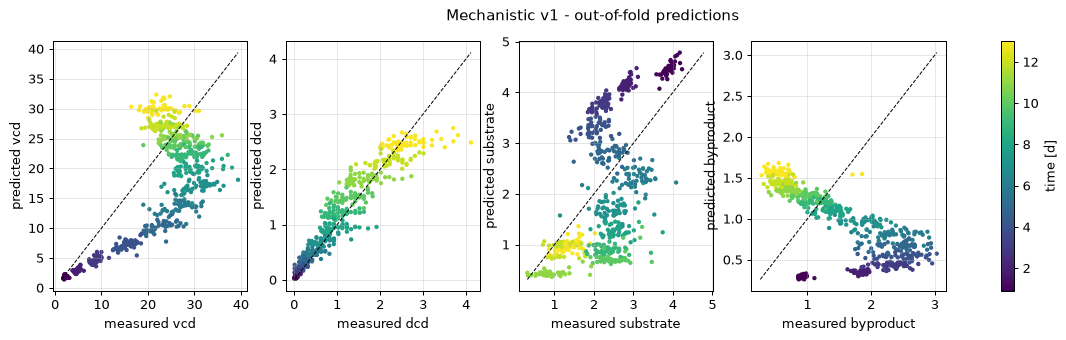

In [5]:
fig = E.parity_plot(cv["mechanistic v1"], title="Mechanistic v1 - out-of-fold predictions")
fig.savefig(FIG_DIR / "parity_v1.png", bbox_inches="tight")

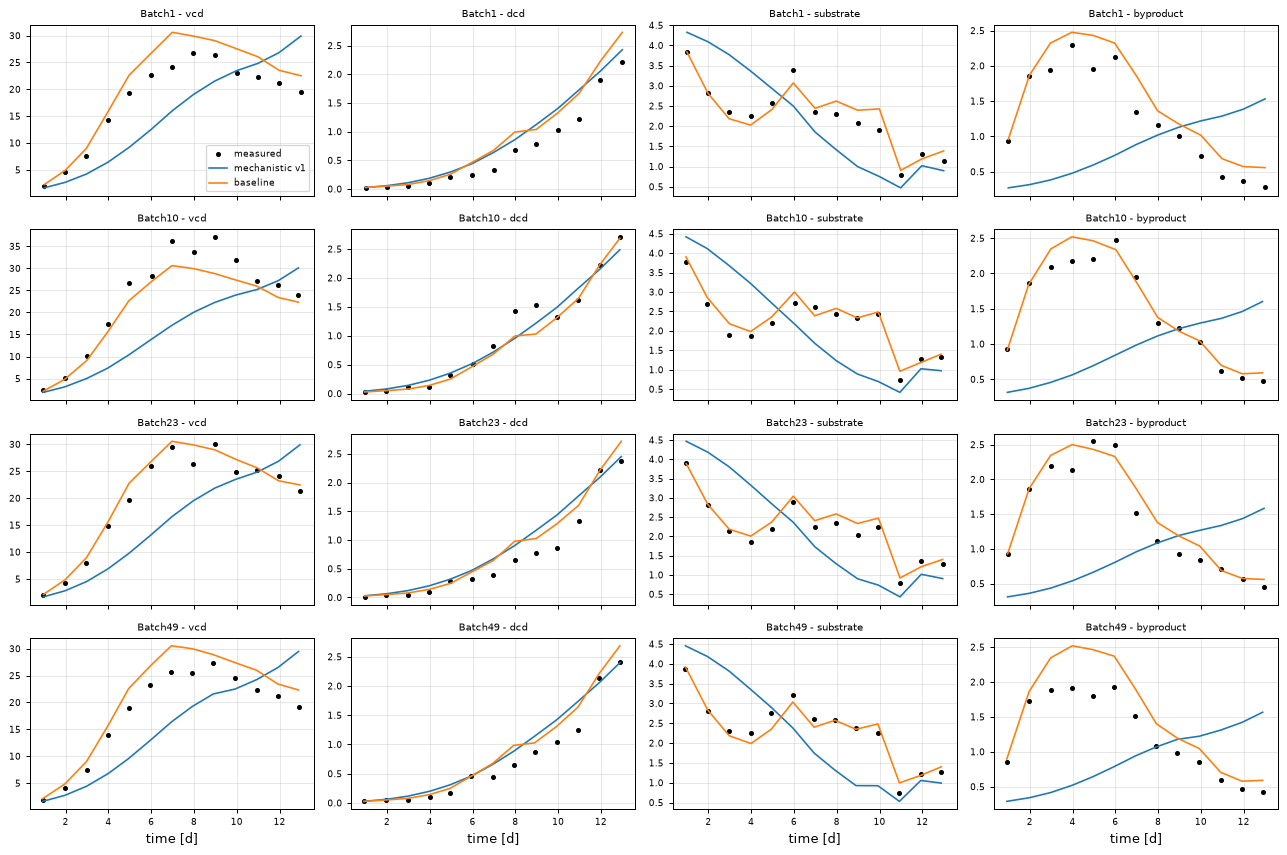

In [6]:
show = ["Batch1", "Batch10", "Batch23", "Batch49"]
fig = E.plot_pred_vs_meas(cv["mechanistic v1"], show,
                          models={"mechanistic v1": cv["mechanistic v1"], "baseline": cv["baseline mean curve"]})
fig.savefig(FIG_DIR / "pred_vs_meas_v1.png", bbox_inches="tight")

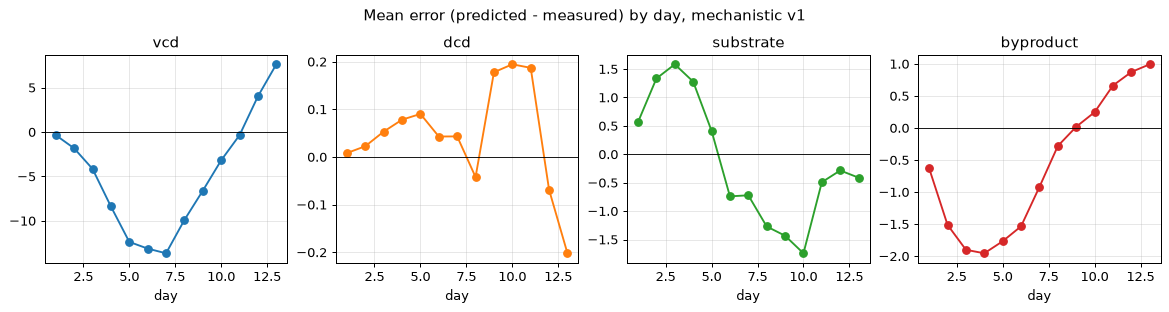

In [7]:
# Where does it fail? Mean error (bias) per culture day, out-of-fold
d = cv["mechanistic v1"].copy(); d["day"] = d["elapsed_time"].round().astype(int)
bias = pd.DataFrame({v: (d[f"{v}_pred"] - d[v]).groupby(d["day"]).mean() for v in ["vcd", "dcd", "substrate", "byproduct"]})
ax = bias.plot(subplots=True, layout=(1, 4), figsize=(16, 3), marker="o", legend=False, title=list(bias.columns))
for a in ax.flat: a.axhline(0, color="k", lw=0.7); a.set_xlabel("day")
plt.suptitle("Mean error (predicted - measured) by day, mechanistic v1", y=1.05)
plt.savefig(FIG_DIR / "bias_by_day_v1.png", bbox_inches="tight")

## 4. Diagnosis

**Out-of-fold result: v1 is much worse than the baseline** (relative RMSE: VCD 40 % vs 12 %, substrate 48 % vs 12 %,
byproduct 80 % vs 14 %). Only DCD is comparable (≈ 29 %). This is the expected "simple version" failure and it
tells us exactly what is missing:

1. **Growth (VCD)**: too slow early (−13 at day 6-7) and still growing at day 13 (+8). A Monod term on substrate
   cannot produce fast exponential growth followed by a plateau/decline while substrate stays at 2-3 g/L.
   The optimiser pushes Ks to its bound to use substrate as a brake. → a **growth brake independent of S**
   is needed (density limitation, hidden nutrient supplied by Feed B, or time/age effect) and probably a
   **death rate that increases late**, so that VCD declines after day 8.
2. **Substrate**: measured substrate drops fast in days 0-3 when there are few cells → the **specific uptake rate is
   high at the start and falls later** (≈ 0.5 → 0.1). A constant yield (Pirt) cannot do this. Since the byproduct is
   produced exactly in the same window, this looks like **overflow metabolism**: excess substrate uptake is turned
   into byproduct.
3. **Byproduct**: Luedeking-Piret only produces (α, β ≥ 0), so P rises monotonically; the measured P peaks at
   day 4-5 then is **consumed**. → byproduct formation must be tied to substrate uptake (overflow) and a
   **consumption term** is needed once growth slows / substrate uptake drops.
4. **C_b ≈ 13** (vs ≈ 50 from the direct mass balance) is distorted by the wrong uptake model; C_sub ≈ 190 is in the
   expected range.

**Next version (v2)**, adding one mechanism at a time and keeping it only if the CV error improves:
- (a) substrate uptake with its own saturation: qS = qS_max · S/(K_S + S), growth from uptake (μ = Yxs·qS) and
  a growth brake (candidates: logistic 1 − Xv/Xmax, hidden nutrient from Feed B, age effect);
- (b) overflow + consumption for the byproduct: qP = Y_PS·qS − qP_cons · P/(K_P + P) (consumption when uptake is low);
- (c) death rate increasing late (e.g. kd·(1 + function of low substrate or accumulated stress)).
